In [54]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../GPs.jl")
include("../functions.jl")
include("../myfuncs.jl")
include("../integrators.jl")
include("../util_shoji.jl")


simulate_pf_selforg (generic function with 1 method)

Maximum error = 0.0008084398633819954
L2 error       = 0.000601071860383032


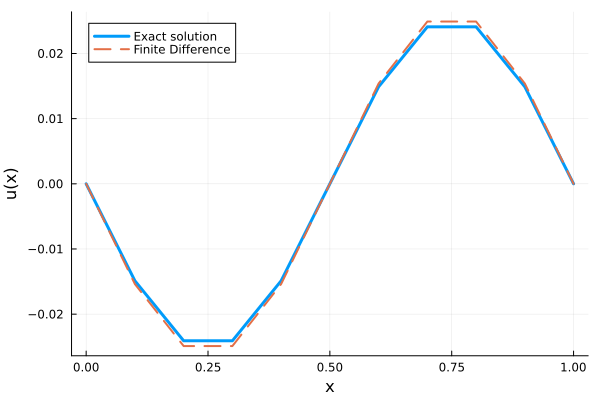

In [55]:
using LinearAlgebra
using Plots

# -----------------------------
# Problem setting
# -----------------------------

dt = 0.1
T = 1.0
x = 0:dt:T

#N = 100                    
#h = 1.0 / N
#x = collect(0:h:1)

# Interior points
xi = x[2:end-1]
n = length(xi)

# -----------------------------
# Construct finite difference matrix
# -u'' = f
# -----------------------------
A = zeros(n, n)

for i in 1:n
    A[i,i] = 2.0
    if i > 1
        A[i,i-1] = -1.0
    end
    if i < n
        A[i,i+1] = -1.0
    end
end

A ./= (dt)^2

# Right-hand side
f = -sin.(2π .* xi)

# Solve linear system
u_interior = A \ f

# Include boundary values
u_num = vcat(0.0, u_interior, 0.0)

# -----------------------------
# Exact solution
# -----------------------------
u_exact_vec = -(1/(2π)^2) .* sin.(2π .* x)

# -----------------------------
# Error
# -----------------------------
max_error = maximum(abs.(u_num .- u_exact_vec))
l2_error = sqrt(sum((u_num .- u_exact_vec).^2) * (dt))

println("Maximum error = ", max_error)
println("L2 error       = ", l2_error)

# -----------------------------
# Plot
# -----------------------------
plot(x, u_exact_vec,
    lw=3,
    label="Exact solution",
    xlabel="x",
    ylabel="u(x)")

plot!(x, u_num,
    linestyle=:dash,
    lw=2,
    label="Finite Difference")

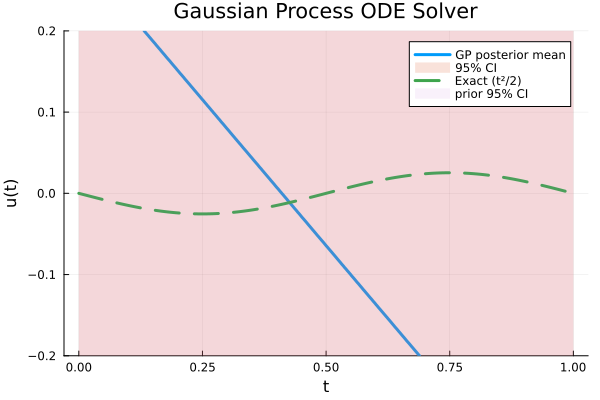

x_obs:[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


"/Users/shoji/Project_with_Jon/Poisson Equation/a.png"

In [56]:
using LinearAlgebra
using Plots



ℓ =10.0
σf =10.0
prior_mean = 0.0
obs_noise = dt^4


function K_LL(ts; dt, ℓ=1.0, σf=1.0)

    n = length(ts)

    K = zeros(n,n)

    for i in 1:n
        for j in 1:n

            ti = ts[i]
            tj = ts[j]

            K[i,j] =
            (
                -rbf_kernel(ti+dt,tj+dt)
                +2rbf_kernel(ti,tj+dt)
                -rbf_kernel(ti-dt,tj+dt)

                +2rbf_kernel(ti+dt,tj)
                -4rbf_kernel(ti,tj)
                +2rbf_kernel(ti-dt,tj)

                -rbf_kernel(ti+dt,tj-dt)
                +2rbf_kernel(ti,tj-dt)
                -rbf_kernel(ti-dt,tj-dt)
            )/dt^4

        end
    end

    K
end

# =====================================================
# Observation covariance
# observations:
# [u(0),
#  L0u,
#  L1u,
#  ...]
# =====================================================

function build_observation_covariance(ts;
                                      dt,
                                      ℓ,
                                      σf)

    n = length(ts)

    K = zeros(n+2,n+2)


    K[1,1] =
        rbf_kernel(
            0.0,
            0.0;
            ℓ=ℓ,
            σf=σf
        )

    K[end,end] =
        rbf_kernel(
            1.0,
            1.0;
            ℓ=ℓ,
            σf=σf
        )


    for j in 1:n

        tj = ts[j]

        K[1,j+1] =
            (
            2* rbf_kernel(
                    0.0,
                    tj;
                    ℓ=ℓ,
                    σf=σf)
            -    rbf_kernel(
                    0.0,
                    tj+dt;
                    ℓ=ℓ,
                    σf=σf
                )


                ) / dt^2

        K[j+1,1] =
            K[1,j+1]

        K[end,j+1] =
            (
            2* rbf_kernel(
                    1.0,
                    tj;
                    ℓ=ℓ,
                    σf=σf)
            -    rbf_kernel(
                    1.0,
                    tj - dt;
                    ℓ=ℓ,
                    σf=σf
                )
            


                ) / dt^2

        K[j+1,end] =
            K[end,j+1]

    end

    


    K[2:end-1,2:end-1] .=
        K_LL(
            ts;
            dt=dt,
            ℓ=ℓ,
            σf=σf
        )

    K
end

# =====================================================
# Cov(u(t),L_j)
# =====================================================

function K_starL(X_test,
                 ts;
                 dt,
                 ℓ=1.0,
                 σf=1.0)

    m = length(X_test)
    n = length(ts)

    K = zeros(m,n)

    for i in 1:m
        for j in 1:n

            t = X_test[i]
            tj = ts[j]

            K[i,j] =
                (
                    2*rbf_kernel(t,tj; ℓ=ℓ, σf=σf) 
                    - rbf_kernel(t,tj+dt; ℓ=ℓ, σf=σf)
                    - rbf_kernel(t,tj-dt; ℓ=ℓ, σf=σf)
                    
                ) / dt^2

        end
    end

    K
end



# =====================================================
# Cross covariance
#
# Cov(u(t), observations)
# =====================================================

function build_cross_covariance(X_test,
                                ts;
                                dt,
                                ℓ,
                                σf)

    m = length(X_test)
    n = length(ts)

    K = zeros(m,n+2)

    #
    # Cov(u(t),u(0))
    #

    for i in 1:m

        K[i,1] =
            rbf_kernel(
                X_test[i],
                0.0;
                ℓ=ℓ,
                σf=σf
            )

        
        K[i,end] =
            rbf_kernel(
                X_test[i],
                1.0;
                ℓ=ℓ,
                σf=σf
            )

    end

    #
    # Cov(u(t),Lj)
    #

    K[:,2:end-1] .=
        K_starL(
            X_test,
            ts;
            dt=dt,
            ℓ=ℓ,
            σf=σf
        )

    K
end

# =====================================================
# ODE
#
# u'(t)=t
#
# exact:
# u(t)=t²/2
# =====================================================


x_obs = collect(dt:dt:1-dt)

println("x_obs:", x_obs)

rhs = -sin.(2π .* x_obs)

  
y = vcat(
    [0.0],
    rhs,
    [0.0]
)




# =====================================================
# Posterior
# =====================================================

X_test =
    collect(
        range(
            0.0,
            1.0,
            length=500
        )
    )

K =
    build_observation_covariance(
        x_obs;
        dt=dt,
        ℓ=ℓ,
        σf=σf
    )

#K += 1e-10I


#Observation Noise
#K[2:end-1,2:end-1] += obs_noise .* I

Ks =
    build_cross_covariance(
        X_test,
        x_obs;
        dt=dt,
        ℓ=ℓ,
        σf=σf
    )

Kss =
    kernel_matrix(
        X_test,
        X_test;
        ℓ=ℓ,
        σf=σf
    )

m_y = vcat([prior_mean],  zeros(length(x_obs)), [prior_mean])
m_x = fill(prior_mean, length(X_test))

μ =   
 m_x + Ks * (K \ (y-m_y))




Σ =
    Kss -
    Ks * (K \ Ks')

std =
    sqrt.(max.(diag(Σ),0))

# =====================================================
# Exact solution
# =====================================================



u_exact(t) = -(1/(2π)^2) * sin(2π * t)


# =====================================================
# Plot
# =====================================================

plot(
    X_test,
    μ,
    lw=3,
    label="GP posterior mean"
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=
        μ .- 1.96 .* std,
    fillalpha=0.2,
    linealpha=0,
    label="95% CI"
)

plot!(
    X_test,
    u_exact.(X_test),
    lw=3,
    ls=:dash,
    label="Exact (t²/2)"
)

μ_prior = zeros(length(X_test))

Kss = kernel_matrix(
    X_test,
    X_test;
    ℓ=ℓ,
    σf=σf
)

std_prior = sqrt.(diag(Kss))


μ_prior = fill(prior_mean, length(X_test))

plot!(
    X_test,
    ylims = (-0.2, 0.2),
    μ_prior .+ 1.96 .* std_prior,
    fillrange = μ_prior .- 1.96 .* std_prior,
    fillalpha = 0.1,
    linealpha = 0,
    label = "prior 95% CI"
)

xlabel!("t")
ylabel!("u(t)")
title!("Gaussian Process ODE Solver")

display(current())

savefig("a.png")

In [65]:
x_obs = collect(dt:dt:1-dt)
n = length(x_obs)
Ktest = kernel_matrix(X_test, x_obs)

function laplacian_matrix(n, dt)

    D = zeros(n,n)

    for i in 1:n

        D[i,i] = -2

        if i > 1
            D[i,i-1] = 1
        end

        if i < n
            D[i,i+1] = 1
        end

    end

    D ./= dt^2

    return D
end

println("D:", D)

Kuu = kernel_matrix(
    x_obs,
    x_obs;
    ℓ=ℓ,
    σf=σf
)

D = laplacian_matrix(length(x_obs), dt)

KLL = D * Kuu * D'

KuL = Kuu * D'

KLu = D * Kuu



e0 = zeros(1,n)
e0[1] = 1

e1 = zeros(1,n)
e1[end] = 1

H = [
    e0
    D
    e1
]

Kobs = H * Kuu * H'

Ks = Ktest * H'

D:[-199.99999999999997 99.99999999999999 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 99.99999999999999 -199.99999999999997 99.99999999999999 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 99.99999999999999 -199.99999999999997 99.99999999999999 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 99.99999999999999 -199.99999999999997 99.99999999999999 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 99.99999999999999 -199.99999999999997 99.99999999999999 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 99.99999999999999 -199.99999999999997 99.99999999999999 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 99.99999999999999 -199.99999999999997 99.99999999999999 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 99.99999999999999 -199.99999999999997 99.99999999999999; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 99.99999999999999 -199.99999999999997]


500×11 Matrix{Float64}:
 0.995012  -100.983   -0.938739  -0.867994  …  -0.261673   -60.7805  0.666977
 0.99521   -100.983   -0.939891  -0.869655     -0.264412   -60.9046  0.66818
 0.995403  -100.983   -0.941033  -0.871307     -0.267152   -61.0288  0.669382
 0.995593  -100.983   -0.942164  -0.872949     -0.269894   -61.153   0.670583
 0.995778  -100.982   -0.943284  -0.874582     -0.272637   -61.2772  0.671784
 0.99596   -100.98    -0.944393  -0.876205  …  -0.275381   -61.4014  0.672985
 0.996138  -100.979   -0.945492  -0.877818     -0.278125   -61.5255  0.674185
 0.996311  -100.977   -0.946579  -0.879422     -0.280871   -61.6497  0.675384
 0.996481  -100.974   -0.947655  -0.881016     -0.283618   -61.7739  0.676583
 0.996647  -100.971   -0.94872   -0.8826       -0.286366   -61.898   0.677782
 ⋮                                          ⋱                        ⋮
 0.676583   -61.7739  -0.283618  -0.42092      -0.947655  -100.974   0.996481
 0.675384   -61.6497  -0.280871  -0.418182     -

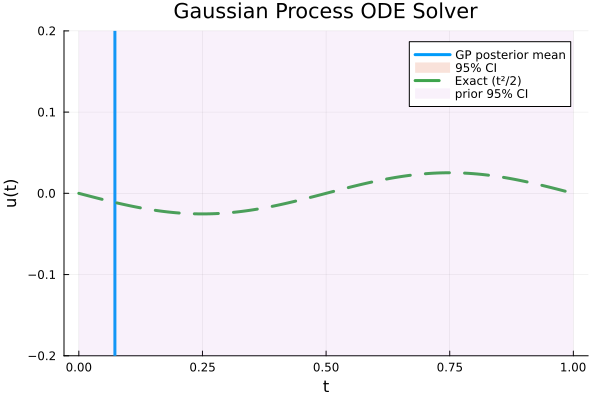

"/Users/shoji/Project_with_Jon/Poisson Equation/a.png"

In [64]:
m_y = vcat([prior_mean],  zeros(length(x_obs)), [prior_mean])
m_x = fill(prior_mean, length(X_test))

μ =   
 m_x + Ks * (K \ (y-m_y))




Σ =
    Kss -
    Ks * (K \ Ks')

std =
    sqrt.(max.(diag(Σ),0))

# =====================================================
# Exact solution
# =====================================================



u_exact(t) = -(1/(2π)^2) * sin(2π * t)


# =====================================================
# Plot
# =====================================================

plot(
    X_test,
    μ,
    lw=3,
    label="GP posterior mean"
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=
        μ .- 1.96 .* std,
    fillalpha=0.2,
    linealpha=0,
    label="95% CI"
)

plot!(
    X_test,
    u_exact.(X_test),
    lw=3,
    ls=:dash,
    label="Exact (t²/2)"
)

μ_prior = zeros(length(X_test))

Kss = kernel_matrix(
    X_test,
    X_test;
    ℓ=ℓ,
    σf=σf
)

std_prior = sqrt.(diag(Kss))


μ_prior = fill(prior_mean, length(X_test))

plot!(
    X_test,
    ylims = (-0.2, 0.2),
    μ_prior .+ 1.96 .* std_prior,
    fillrange = μ_prior .- 1.96 .* std_prior,
    fillalpha = 0.1,
    linealpha = 0,
    label = "prior 95% CI"
)

xlabel!("t")
ylabel!("u(t)")
title!("Gaussian Process ODE Solver")

display(current())

savefig("a.png")